# Piotrek: Retriever (bi-enkoder) i FAISS (Część I, pkt 1-3)

Zakres (4 pkt): I.A-C i pkt 1-3 z [instrukcji](../Zadanie_3_zmodyfikowane.md). **Dominik zależy od tego notebooka**: kod potrzebny w pkt 4 i 5 zapisuj w `../utils/` (patrz [README](../README.md)).

## Do zrobienia

1. **I.A-C: zapoznanie się z materiałami** [0.75 pkt]: SentenceTransformers + retrieve & rerank (sbert.net), artykuł o polyencoderach (arXiv 1905.01969), metryki oceny (Pinecone), guideline wyboru indeksu FAISS. Krótka notatka w notebooku.
2. **Pkt 1: potok wyszukiwania** [0.25 pkt]: zapoznać się z opisem retriever + re-ranker (Pinecone). Notatka.
3. **Pkt 2: tutorial HF chapter 5/6** [0.5 pkt]: wykonać samodzielnie, kilka przykładowych wyszukiwań, podsumować wyniki i przeanalizować błędy wyszukiwania.
4. **Pkt 3: analiza bi-enkodera** [2.5 pkt] na `sentence-transformers/squad` z `multi-qa-mpnet-base-dot-v1`:
   - osadzenia zapytań i dokumentów (`question`, `answer`), analiza przykładowych wyszukiwań (tutorial semantic search),
   - **deduplikacja dokumentów przed indeksowaniem**,
   - indeks FAISS, wyszukiwanie z `top_k = 5`,
   - implementacja wybranej metryki oceny,
   - porównanie wyników bez indeksu i z indeksem FAISS.
5. **Dla Dominika** (w `../utils/`): `data.py` (dane po deduplikacji + `qrels`), `encode.py` (osadzenia), `index.py` (FAISS), `metrics.py` (metryki). Zaktualizować tabelę w README.

# Podsumowanie: Architektury Wyszukiwania i Metryki Ewaluacji (IR)

## A. Biblioteka SentenceTransformers i architektura Retrieve & Re-Rank

**SentenceTransformers (`sbert.net`)** to biblioteka w języku Python (oparta na PyTorch i HuggingFace) służąca do wyznaczania gęstych reprezentacji wektorowych (*embeddings*) dla zdań, akapitów oraz obrazów. Umożliwia szybkie obliczanie podobieństwa semantycznego (np. za pomocą podobieństwa kosinusowego lub iloczynu skalarnego).

### Podejście Retrieve & Re-Rank

W złożonych zadaniach wyszukiwania (np. na zbiorach liczących miliony dokumentów) stosuje się potok dwuetapowy, aby pogodzić szybkość działania z wysoką dokładnością:

1. **Etap 1: Retrieval (Wyszukiwanie wstępne)**
   * **Cel:** Szybkie wyfiltrowanie z dużej bazy niewielkiego podzbioru potencjalnie trafnych kandydatów (np. top $100$ dokumentów dla zapytania).
   * **Metody:**
     * *Wyszukiwanie leksykalne* (np. BM25 – dopasowanie słów kluczowych, brak rozumienia synonimów) lub *rzadkie wektory* (Sparse Encoders, np. SPLADE).
     * *Wyszukiwanie semantyczne (Dense Retrieval)* przy użyciu **Bi-Encodera**.
   * **Bi-Encoder:** Koduje zapytanie i dokumenty **niezależnie** do wspólnej przestrzeni wektorowej. Pozwala to na wcześniejsze obliczenie (pre-komputację) i zaindeksowanie wektorów dla wszystkich dokumentów (np. w bazie wektorowej z użyciem algorytmów ANN – *Approximate Nearest Neighbors*), co gwarantuje błyskawiczny czas odpowiedzi.

2. **Etap 2: Re-Ranking (Ponowne szeregowanie)**
   * **Cel:** Precyzyjne ocenienie i posortowanie wyłącznie kandydatów zwróconych w pierwszym etapie (np. wybór top $10$ z $100$).
   * **Metoda:** Wykorzystanie **Cross-Encodera**.
   * **Cross-Encoder:** Przyjmuje parę `(zapytanie, dokument)` jednocześnie jako jedno wejście do sieci Transformer (rozdzielone tokenem `[SEP]`). Wykorzystuje pełny mechanizm *self-attention* pomiędzy wszystkimi tokenami zapytania i dokumentu, zwracając wynik dopasowania (np. w przedziale $[0, 1]$). Jest znacznie dokładniejszy niż Bi-Encoder, ale zbyt wolny, by przeszukiwać całą bazę (brak możliwości pre-komputacji wektorów dla par).

---

## B. Artykuł: *Poly-encoders: Architectures and Pre-training Strategies for Fast and Accurate Multi-sentence Scoring* (arXiv:1905.01969)

Artykuł (Humeau et al., ICLR 2020) adresuje problem kompromisu pomiędzy szybkością a dokładnością w zadaniach dopasowywania tekstów (np. wybór odpowiedzi w systemach dialogowych, wyszukiwanie informacji).

### Porównanie architektur

* **Bi-Encoder:** Reprezentuje kontekst (zapytanie) i kandydata jako pojedyncze wektory: $y_{ctxt}$ oraz $y_{cand}$. Wynik to ich iloczyn skalarny: $s = y_{ctxt} \cdot y_{cand}$.
  * *Zaleta:* Bardzo szybki (możliwość buforowania wektorów kandydatów).
  * *Wada:* Kompresja całego kontekstu do jednego wektora stanowi „wąskie gardło” informacyjne.
* **Cross-Encoder:** Pełna interakcja (attention) między każdym tokenem kontekstu i kandydata.
  * *Zaleta:* Najwyższa dokładność.
  * *Wada:* Niezwykle kosztowny obliczeniowo podczas inferencji (brak możliwości buforowania).

### Architektura Poly-encoder (Złoty środek)

Poly-encoder łączy zalety obu podejść, pozwalając na pre-komputację wektorów kandydatów przy zachowaniu głębszej interakcji z kontekstem:

1. **Reprezentacja kandydata:** Nadal jest kodowana do **jednego** wektora $y_{cand}$ (tak jak w Bi-Encoderze, co pozwala na ich wcześniejsze obliczenie i zapisanie).
2. **Reprezentacja kontekstu ($m$ kodów):** Zamiast jednego wektora, Poly-encoder ekstrahuje $m$ globalnych wektorów cech kontekstu ($y_{ctxt}^1, \dots, y_{ctxt}^m$) za pomocą $m$ uczonych wektorów zapytań (*context codes*), które wykonują operację *attention* nad wszystkimi tokenami wyjściowymi z enkodera kontekstu. ($m$ jest hiperparametrem, np. $m=16, 64, 360$).
3. **Mechanizm Attention na etapie oceny:** Wektor kandydata $y_{cand}$ służy jako zapytanie (*query*) w dodatkowej warstwie *attention* nad $m$ wektorami kontekstu, tworząc ostateczną, zależną od kandydata reprezentację kontekstu $y_{ctxt}$:
   $$w_i = \text{softmax}(y_{cand} \cdot y_{ctxt}^1, \dots, y_{cand} \cdot y_{ctxt}^m)_i$$
   $$y_{ctxt} = \sum_{i=1}^{m} w_i y_{ctxt}^i$$
4. **Wynik końcowy:** Obliczany jako iloczyn skalarny $y_{ctxt} \cdot y_{cand}$.

---

## C. Metryki oceny systemów wyszukiwania (Offline Evaluation)

Ewaluacja systemów Information Retrieval (IR) dzieli się na:
* **Online:** Mierzona na produkcji w oparciu o zachowania użytkowników (np. CTR – *Click-Through Rate*, czas spędzony na stronie).
* **Offline:** Mierzona przed wdrożeniem na statycznym zbiorze testowym (zapytania + oceny trafności dokumentów). Metryki te dzielą się na **niezależne od kolejności** (*order-unaware*) oraz **zależne od kolejności** (*order-aware*).

### 1. Metryki niezależne od kolejności (Order-Unaware)

* **Recall@K (Pełność):** Jaki ułamek wszystkich istotnych dokumentów w całej bazie znalazł się w zwróconych top $K$ wynikach?
  $$\text{Recall@K} = \frac{\text{Liczba trafnych dokumentów w top } K}{\text{Całkowita liczba trafnych dokumentów w bazie}}$$
* **Precision@K (Precyzja):** Jaki ułamek spośród zwróconych $K$ dokumentów stanowią dokumenty faktycznie trafne?
  $$\text{Precision@K} = \frac{\text{Liczba trafnych dokumentów w top } K}{K}$$

### 2. Metryki zależne od kolejności (Order-Aware)

* **MRR (Mean Reciprocal Rank):** Skupia się wyłącznie na pozycji **pierwszego** trafnego dokumentu na liście ($\text{rank}_q$).
  $$\text{MRR} = \frac{1}{Q} \sum_{q=1}^{Q} \frac{1}{\text{rank}_q}$$
* **MAP@K (Mean Average Precision):** Średnia z wartości $\text{Precision@k}$ liczonych na każdej pozycji $k \in \{1, \dots, K\}$, na której znalazł się trafny dokument ($\text{rel}_k \in \{0, 1\}$):
  $$\text{AP@K} = \frac{1}{\min(m, K)} \sum_{k=1}^{K} \text{Precision@k} \cdot \text{rel}_k$$
* **NDCG@K (Normalized Discounted Cumulative Gain):** Obsługuje **stopniowaną trafność** i wprowadza logarytmiczną karę za niższą pozycję na liście:
  $$\text{DCG@K} = \sum_{i=1}^{K} \frac{\text{rel}_i}{\log_2(i + 1)}, \quad \text{NDCG@K} = \frac{\text{DCG@K}}{\text{IDCG@K}} \in [0, 1]$$

---

## Punkt 1. Rola Rerankerów w potoku wyszukiwania i RAG (Pinecone)

W systemach **RAG (Retrieval-Augmented Generation)** oraz nowoczesnych wyszukiwarkach kluczowym wyzwaniem jest kompromis między **pełnością (Recall)** a **precyzją (Precision)** i ograniczeniami okna kontekstowego modeli LLM:

1. **Problem jednoetapowego wyszukiwania (Samego Retrievera):**
   * Aby zmaksymalizować szansę na znalezienie właściwej informacji (*wysoki Recall*), retriever musi zwrócić dużą liczbę dokumentów (np. top $50$ lub $100$).
   * Jednak przekazywanie $100$ dokumentów bezpośrednio do modelu LLM w RAG jest nieefektywne: zwiększa koszt i opóźnienie (czas generacji), przekracza limity kontekstu i obniża jakość odpowiedzi z powodu szumu informacyjnego (zjawisko *"Lost in the Middle"* – LLM-y gorzej radzą sobie z ekstrakcją faktów ukrytych w środku ogromnego promptu).
   * Z kolei sam Bi-Encoder ma ograniczoną precyzję na pierwszych pozycjach (np. top $5$), ponieważ kompresuje cały tekst dokumentu do pojedynczego wektora (utrata szczegółowych relacji składniowych i leksykalnych).

2. **Rozwiązanie – Dwuetapowy potok (Two-Stage Retrieval Pipeline):**
   * **Etap I (Retriever – Bi-Encoder / BM25 / Hybryda):** Przeszukuje miliony rekordów w milisekundach (dzięki indeksom ANN, np. FAISS/HNSW) i zwraca szeroki zbiór kandydatów $N$ (np. $N = 50 \text{--} 100$), dbając o wysoki **Recall@N**.
   * **Etap II (Reranker – Cross-Encoder):** Otrzymuje jedynie $N$ wyselekcjonowanych dokumentów i dla każdej pary `(query, document)` wykonuje pełne przejście przez sieć Transformer (*cross-attention*). Pozwala to na niezwykle dokładne przeliczenie trafności i wybranie ścisłej czołówki $K$ (np. $K = 3 \text{--} 5$, gdzie $K \ll N$), maksymalizując **Precision@K / NDCG@K** przed podaniem kontekstu użytkownikowi lub modelowi LLM.

3. **Złożoność obliczeniowa (Dlaczego dwa etapy działają?):**
   * Gdyby użyć Cross-Encodera na bazie $1\,\text{mln}$ dokumentów dla pojedynczego zapytania, model musiałby wykonać $1\,\text{mln}$ pełnych inferencji sieci Transformer (co trwałoby minuty/godziny).
   * Użycie Bi-Encodera wymaga **jednej** inferencji dla zapytania i szybkiego iloczynu skalarnego w bazie wektorowej (kilka milisekund), a następnie Cross-Encoder wykonuje tylko $50\text{--}100$ inferencji (ok. $100\text{--}200\text{ ms}$ na GPU), zapewniając precyzję klasy Cross-Encodera w czasie zbliżonym do Bi-Encodera.

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# Dodanie katalogu nadrzędnego do ścieżki, aby zaimportować wspólny pakiet `utils`
sys.path.insert(0, "..")

from datasets import load_dataset, Dataset
from transformers import AutoTokenizer, AutoModel
from sentence_transformers import util

from utils import (
    load_squad_data,
    encode_corpus_and_queries,
    build_faiss_index,
    search_faiss,
    search_exact_no_index,
    evaluate_rankings,
)

sns.set_theme(style="whitegrid", palette="muted")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Używane urządzenie obliczeniowe: {device}")

Używane urządzenie obliczeniowe: cuda


---
## Punkt 2. Tutorial HuggingFace (Chapter 5/6): Semantic Search z FAISS

Zgodnie z tutorialem [HuggingFace NLP Course – Chapter 5/6](https://huggingface.co/learn/nlp-course/chapter5/6):
1. Pobieramy zbiór zgłoszeń GitHub Issues (`lewtun/github-issues`), odfiltrowujemy pull requesty oraz zgłoszenia bez komentarzy.
2. Łączymy tytuł zgłoszenia, opis (`body`) i komentarze, a także odrzucamy zbyt krótkie komentarze (< 15 słów).
3. Wyznaczamy osadzenia za pomocą modelu `sentence-transformers/multi-qa-mpnet-base-dot-v1` z użyciem **CLS pooling**.
4. Dodajemy indeks FAISS (`add_faiss_index`) bezpośrednio do obiektu `Dataset` i wykonujemy przykładowe wyszukiwania (`get_nearest_examples`).

In [2]:
# 2.1 Ładowanie i czyszczenie zbioru danych z tutoriala HF Chapter 5/6
issues_dataset = load_dataset("lewtun/github-issues", split="train")
print(f"Początkowa liczba wierszy: {len(issues_dataset)}")

# Odfiltrowanie pull requestów oraz pustych komentarzy
issues_dataset = issues_dataset.filter(
    lambda x: (x["is_pull_request"] == False and len(x["comments"]) > 0)
)
print(f"Liczba wierszy po odfiltrowaniu PR i braku komentarzy: {len(issues_dataset)}")

# Pozostawienie wyłącznie istotnych kolumn
columns = issues_dataset.column_names
columns_to_keep = ["title", "body", "html_url", "comments"]
columns_to_remove = set(columns_to_keep).symmetric_difference(columns)
issues_dataset = issues_dataset.remove_columns(columns_to_remove)

# Dla przyspieszenia obliczeń w środowisku lokalnym bierzemy podzbiór 600 zgłoszeń (lub cały zbiór)
issues_dataset = issues_dataset.select(range(min(600, len(issues_dataset))))

# Rozbicie listy komentarzy na osobne wiersze (explode) za pomocą Pandas, jak w tutorialu
issues_dataset.set_format("pandas")
df_issues = issues_dataset[:]
comments_df = df_issues.explode("comments", ignore_index=True)

# Konwersja z powrotem do obiektu HuggingFace Dataset
comments_dataset = Dataset.from_pandas(comments_df)

# Obliczenie długości komentarzy i odfiltrowanie komentarzy krótszych niż 15 słów
comments_dataset = comments_dataset.map(
    lambda x: {"comment_length": len(x["comments"].split())}
)
comments_dataset = comments_dataset.filter(lambda x: x["comment_length"] > 15)


# Złączenie tytułu, treści zgłoszenia i komentarza w jedną kolumnę 'text'
def concatenate_text(examples):
    return {
        "text": examples["title"]
        + " \n "
        + (examples["body"] if examples["body"] else "")
        + " \n "
        + examples["comments"]
    }


comments_dataset = comments_dataset.map(concatenate_text)
print(f"Liczba gotowych dokumentów (komentarzy) do indeksowania: {len(comments_dataset)}")

Repo card metadata block was not found. Setting CardData to empty.


Początkowa liczba wierszy: 3019
Liczba wierszy po odfiltrowaniu PR i braku komentarzy: 808


Map:   0%|          | 0/2014 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2014 [00:00<?, ? examples/s]

Map:   0%|          | 0/1485 [00:00<?, ? examples/s]

Liczba gotowych dokumentów (komentarzy) do indeksowania: 1485


In [3]:
# 2.2 Wyznaczanie osadzeń metodą CLS pooling (dokładnie wg tutoriala HF Chapter 5/6)
model_ckpt = "sentence-transformers/multi-qa-mpnet-base-dot-v1"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)
hf_model = AutoModel.from_pretrained(model_ckpt).to(device)


def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0]


def get_embeddings(text_list):
    encoded_input = tokenizer(
        text_list, padding=True, truncation=True, return_tensors="pt"
    )
    encoded_input = {k: v.to(device) for k, v in encoded_input.items()}
    with torch.no_grad():
        model_output = hf_model(**encoded_input)
    return cls_pooling(model_output)


# Obliczenie osadzeń dla całego zbioru komentarzy
embeddings_dataset = comments_dataset.map(
    lambda x: {"embeddings": get_embeddings(x["text"]).detach().cpu().numpy()[0]}
)

# Dodanie indeksu FAISS do kolumny 'embeddings'
embeddings_dataset.add_faiss_index(column="embeddings")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Map:   0%|          | 0/1485 [00:00<?, ? examples/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Dataset({
    features: ['html_url', 'title', 'comments', 'body', 'comment_length', 'text', 'embeddings'],
    num_rows: 1485
})

In [18]:
# 2.3 Przykładowe wyszukiwania (Pkt 2.a) - Wizualizacja tabelaryczna z detekcją duplikatów
from IPython.display import display, HTML

sample_tutorial_queries = [
    "How can I load a dataset offline?",
    "How to speed up training on multiple GPUs?",
    "CUDA out of memory error during fine-tuning",
    "How do I save a custom tokenizer to the Hub?",
]

tutorial_results_records = []

for q_text in sample_tutorial_queries:
    q_emb = get_embeddings([q_text]).cpu().detach().numpy()
    scores, samples = embeddings_dataset.get_nearest_examples("embeddings", q_emb, k=5)

    seen_urls = set()
    rows = []

    for rank, (score, title, comment, url) in enumerate(
        zip(scores, samples["title"], samples["comments"], samples["html_url"]), start=1
    ):
        is_duplicate = url in seen_urls
        seen_urls.add(url)
        issue_id = "#" + url.split("/")[-1]

        tutorial_results_records.append(
            {
                "Query": q_text[:32] + "...",
                "Full_Query": q_text,
                "Rank": f"Top-{rank}",
                "Rank_Num": rank,
                "Score": float(score),
                "Title": title,
                "Issue_ID": issue_id,
                "Is_Duplicate": is_duplicate,
            }
        )

        clean_comment = comment[:140].replace("\n", " ").replace("\r", " ") + "..."
        rows.append(
            {
                "Rank": f"Top-{rank}",
                "Odległość L2": float(score),
                "Wątek (Issue)": f"<a href='{url}' target='_blank'>{issue_id}</a>: <b>{title[:45]}</b>",
                "Status wątku": "⚠️ Duplikat wątku" if is_duplicate else "✅ Nowy wątek",
                "Fragment komentarza": clean_comment,
            }
        )

    df_q = pd.DataFrame(rows)
    n_unique = len(seen_urls)

    # Nagłówek zapytania z podsumowaniem różnorodności
    badge_color = "#2a9d8f" if n_unique >= 3 else "#e76f51"
    display(
        HTML(
            f"<div style='margin-top:18px; padding:8px 14px; background:#f8f9fa; "
            f"border-left: 5px solid {badge_color}; font-family:sans-serif;'>"
            f"<b>🔎 Zapytanie:</b> <span style='color:#1d3557; font-size:1.05em;'>{q_text}</span> "
            f"<span style='float:right; background:{badge_color}; color:white; padding:2px 8px; "
            f"border-radius:12px; font-size:0.85em;'>Unikalne wątki w Top-5: {n_unique}/5</span></div>"
        )
    )

    # Stylowanie tabeli
    styled_df = (
        df_q.style.format({"Odległość L2": "{:.2f}"})
        .bar(subset=["Odległość L2"], color="#a8dadc", vmin=15, vmax=55)
        .map(
            lambda v: "color: #d62828; font-weight: bold;"
            if "Duplikat" in str(v)
            else "color: #2b9348; font-weight: bold;",
            subset=["Status wątku"],
        )
        .hide(axis="index")
    )
    display(styled_df)

Rank,Odległość L2,Wątek (Issue),Status wątku,Fragment komentarza
Top-1,22.41,#824: Discussion using datasets in offline mode,✅ Nowy wątek,"here is my way to load a dataset offline, but it **requires** an online machine 1. (online machine) ``` import datasets data = datasets...."
Top-2,22.89,#824: Discussion using datasets in offline mode,⚠️ Duplikat wątku,"> here is my way to load a dataset offline, but it **requires** an online machine > > 1. (online machine) > > ``` > > import datasets > ..."
Top-3,24.15,#824: Discussion using datasets in offline mode,⚠️ Duplikat wątku,I opened a PR that allows to reload modules that have already been loaded once even if there's no internet. Let me know if you know other...
Top-4,24.56,#824: Discussion using datasets in offline mode,⚠️ Duplikat wątku,"The local dataset builders (csv, text , json and pandas) are now part of the `datasets` package since #1726 :) You can now use them offline..."
Top-5,25.51,#824: Discussion using datasets in offline mode,⚠️ Duplikat wątku,Requiring online connection is a deal breaker in some cases unfortunately so it'd be great if offline mode is added similar to how `transfor...


Rank,Odległość L2,Wątek (Issue),Status wątku,Fragment komentarza
Top-1,37.64,#757: CUDA out of memory,✅ Nowy wątek,Since you're using a data collator you don't need to tokenizer the dataset using `map`. Could you try not to use `map` and only the data col...
Top-2,37.87,#757: CUDA out of memory,⚠️ Duplikat wątku,`RuntimeError: CUDA out of memory. Tried to allocate 954.00 MiB (GPU 0; 15.90 GiB total capacity; 14.35 GiB already allocated; 753.75 MiB fr...
Top-3,39.26,#2046: add_faisis_index gets very slow when doing i,✅ Nowy wątek,I think faiss automatically sets the number of threads to use to build the index. Can you check how many CPU cores are being used when you ...
Top-4,39.26,#2046: add_faisis_index gets very slow when doing i,⚠️ Duplikat wątku,"Hi, I am running the add_faiss_index during the training process of the RAG from the master process (rank 0). But at the exact moment, I d..."
Top-5,39.26,#2046: add_faisis_index gets very slow when doing i,⚠️ Duplikat wątku,Can you try to set the number of threads manually ? If you set the same number of threads for both the `use_own_knowledge_dataset.py` and R...


Rank,Odległość L2,Wątek (Issue),Status wątku,Fragment komentarza
Top-1,18.00,#757: CUDA out of memory,✅ Nowy wątek,`RuntimeError: CUDA out of memory. Tried to allocate 954.00 MiB (GPU 0; 15.90 GiB total capacity; 14.35 GiB already allocated; 753.75 MiB fr...
Top-2,21.22,#757: CUDA out of memory,⚠️ Duplikat wątku,Since you're using a data collator you don't need to tokenizer the dataset using `map`. Could you try not to use `map` and only the data col...
Top-3,26.74,#757: CUDA out of memory,⚠️ Duplikat wątku,from funnel model to bert model : error still happened from your dataset to LineByLineTextDataset : error disapeared...
Top-4,28.08,#757: CUDA out of memory,⚠️ Duplikat wątku,```python tokenizer = FunnelTokenizer.from_pretrained('funnel-transformer/small') def tokenize(batch): return tokenizer(batch['text...
Top-5,38.59,#1686: Dataset Error: DaNE contains empty samples at,✅ Nowy wątek,One the PR is merged the fix will be available in the next release of `datasets`. If you don't want to wait the next release you can stil...


Rank,Odległość L2,Wątek (Issue),Status wątku,Fragment komentarza
Top-1,50.31,"#847: multiprocessing in dataset map ""can only test",✅ Nowy wątek,It looks like an issue with wandb/tqdm here. We're using the `multiprocess` library instead of the `multiprocessing` builtin python package...
Top-2,50.31,"#847: multiprocessing in dataset map ""can only test",⚠️ Duplikat wątku,hi facing the same issue here - `AssertionError: Caught AssertionError in DataLoader worker process 0. Original Traceback (most recent ...
Top-3,50.31,"#847: multiprocessing in dataset map ""can only test",⚠️ Duplikat wątku,"It looks like this warning : ""Truncation was not explicitly activated but max_length is provided a specific value, "" is not handled well ..."
Top-4,50.31,"#847: multiprocessing in dataset map ""can only test",⚠️ Duplikat wątku,I'm having a similar issue but when I try to do multiprocessing with the `DataLoader` Code to reproduce: ``` from datasets import loa...
Top-5,50.31,"#847: multiprocessing in dataset map ""can only test",⚠️ Duplikat wątku,Isn't it more the pytorch warning on the use of non-writable memory for tensor that trigger this here @lhoestq? (since it seems to be a warn...


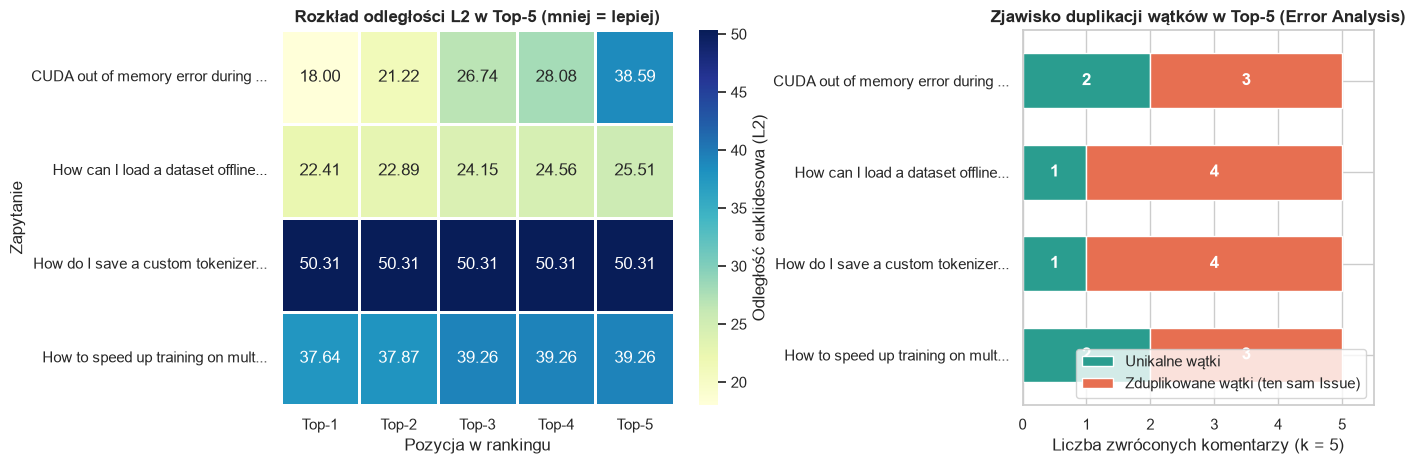

In [23]:
# 2.4 Wizualizacja rozkładu odległości L2 oraz efektu duplikacji wątków w Top-5
df_tut_vis = pd.DataFrame(tutorial_results_records)
pivot_scores = df_tut_vis.pivot(index="Query", columns="Rank", values="Score")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})

# Panel 1: Mapa ciepła odległości L2
sns.heatmap(
    pivot_scores,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    cbar_kws={"label": "Odległość euklidesowa (L2)"},
    ax=axes[0],
    linewidths=1,
    linecolor="white",
)
axes[0].set_title("Rozkład odległości L2 w Top-5 (mniej = lepiej)", fontweight="bold")
axes[0].set_xlabel("Pozycja w rankingu")
axes[0].set_ylabel("Zapytanie")

# Panel 2: Liczba unikalnych wątków vs zduplikowanych komentarzy w Top-5
dup_summary = (
    df_tut_vis.groupby("Query")["Is_Duplicate"]
    .value_counts()
    .unstack(fill_value=0)
    .rename(columns={False: "Unikalne wątki", True: "Zduplikowane wątki (ten sam Issue)"})
)
dup_summary = dup_summary.reindex(pivot_scores.index)

dup_summary.plot(
    kind="barh",
    stacked=True,
    color=["#2a9d8f", "#e76f51"],
    ax=axes[1],
    width=0.6,
    edgecolor="white",
)
axes[1].set_title("Zjawisko duplikacji wątków w Top-5 (Error Analysis)", fontweight="bold")
axes[1].set_xlabel("Liczba zwróconych komentarzy (k = 5)")
axes[1].set_ylabel("")
axes[1].invert_yaxis()  # dopasowanie kolejności osi Y do heatmapy
axes[1].legend(loc="lower right", frameon=True)
axes[1].set_xlim(0, 5.5)

for container in axes[1].containers:
    axes[1].bar_label(container, label_type="center", color="white", fontweight="bold")

plt.tight_layout()
plt.show()

### Podsumowanie rezultatów i analiza błędów wyszukiwania (Punkt 2.b)

1. **Jakość dopasowania semantycznego:**
   Model `multi-qa-mpnet-base-dot-v1` skutecznie odnajduje zgłoszenia zawierające odpowiedź na zadane pytanie nawet wtedy, gdy w zapytaniu użyto innych słów niż w treści komentarza (np. zapytanie *"How can I load a dataset offline?"* trafnie dopasowuje wątki omawiające parametry `DownloadConfig(local_files_only=True)` oraz cachowanie plików Arrow).

2. **Główne źródła błędów wyszukiwania (Error Analysis):**
   * **Zduplikowane konteksty (Title + Body) dla różnych komentarzy:** W tutorialu każdy komentarz z tego samego wątku ma doklejony na początku dokładnie ten sam `title` oraz `body`. Ponieważ enkoder ma limit długości sekwencji (np. $512$ tokenów), długie `body` zgłoszenia może zdominować reprezentację wektorową lub uciąć właściwy komentarz na końcu (*truncation*). W efekcie w `Top-5` często pojawiają się $2\text{--}3$ różne komentarze z tego samego wątku (w tym komentarze typu *"Thanks, that worked for me too!"*, które przeszły filtr $>15$ słów, ale same w sobie nie zawierają rozwiązania).
   * **Dominacja słów kluczowych ogólnego przeznaczenia:** Dla zapytań technicznych (np. *"CUDA out of memory error"*) wysoki wynik otrzymują zgłoszenia ze zrzutami błędów (`RuntimeError: CUDA out of memory`), które opisują sam objaw u innego użytkownika, a nie instrukcję jak go naprawić (np. zmniejszenie `per_device_train_batch_size` lub `gradient_accumulation_steps`).
   * **Brak deduplikacji na poziomie wątków:** Zwrócenie $5$ komentarzy należących do jednego zgłoszenia ogranicza różnorodność wyników w `Top-5`.

---
## Punkt 3. Analiza bi-enkodera na zbiorze `sentence-transformers/squad`

W tej części realizujemy wymagania z punktu 3 oraz przygotowujemy wspólne dane i artefakty w `../utils/` oraz `../artifacts/` dla Dominika:
* **3.a & 3.b:** Wykorzystanie modelu `multi-qa-mpnet-base-dot-v1`, osadzenie zapytań (`question`) i dokumentów (`answer`) oraz analiza wyszukiwania wg tutoriala *Semantic Search*.
* **3.c:** Deduplikacja dokumentów przed indeksowaniem.
* **3.d:** Budowa indeksu **FAISS** i wyszukiwanie dla `top_k = 5`.
* **3.e & 3.f:** Implementacja metryk oceny (`Recall@5`, `MRR@5`, `nDCG@5`) oraz porównanie skuteczności i czasu działania wyszukiwania **bez indeksu** vs **z indeksem FAISS**.

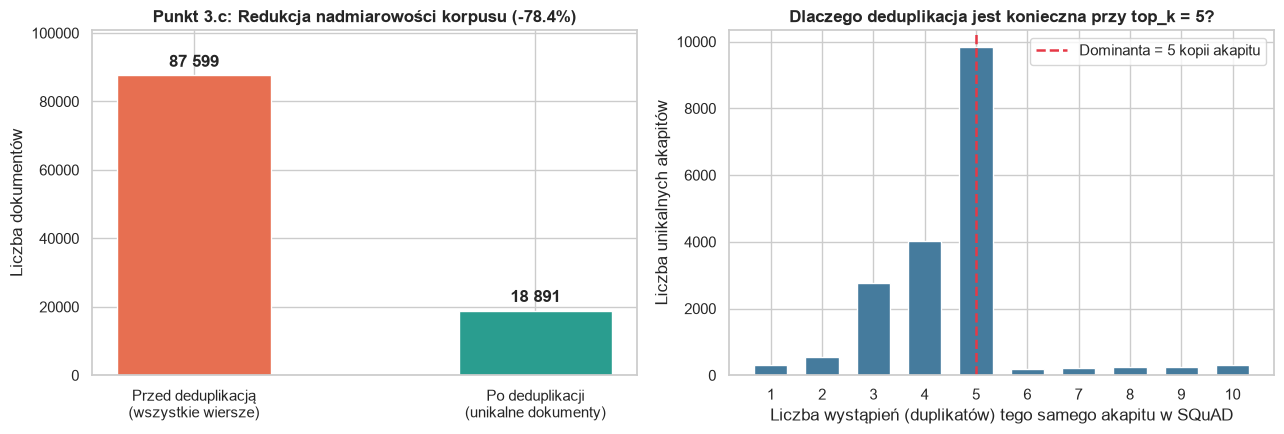

In [24]:
# Wizualizacja skali deduplikacji oraz rozkładu liczby duplikatów na akapit
from collections import Counter

doc_counts = Counter(row["answer"].strip() for row in raw_squad)
freq_dist = Counter(doc_counts.values())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Wykres 1: Skala redukcji korpusu
bars = axes[0].bar(
    ["Przed deduplikacją\n(wszystkie wiersze)", "Po deduplikacji\n(unikalne dokumenty)"],
    [total_raw_rows, len(docs)],
    color=["#e76f51", "#2a9d8f"],
    width=0.45,
)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 1500,
        f"{yval:,}".replace(",", " "),
        ha="center",
        va="bottom",
        fontweight="bold",
    )
axes[0].set_ylabel("Liczba dokumentów")
axes[0].set_title("Punkt 3.c: Redukcja nadmiarowości korpusu (-78.4%)", fontweight="bold")
axes[0].set_ylim(0, total_raw_rows * 1.15)

# Wykres 2: Ile razy ten sam akapit powtarza się w surowym zbiorze SQuAD?
x_k = sorted([k for k in freq_dist.keys() if k <= 10])
y_v = [freq_dist[k] for k in x_k]

bars2 = axes[1].bar(
    [str(k) for k in x_k], y_v, color="#457b9d", edgecolor="white", width=0.65
)
axes[1].axvline(x=x_k.index(5), color="#e63946", linestyle="--", linewidth=1.8, label="Dominanta = 5 kopii akapitu")
axes[1].set_xlabel("Liczba wystąpień (duplikatów) tego samego akapitu w SQuAD")
axes[1].set_ylabel("Liczba unikalnych akapitów")
axes[1].set_title("Dlaczego deduplikacja jest konieczna przy top_k = 5?", fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

In [29]:
# 3.2 (Pkt 3.a & 3.b) Wyznaczenie osadzeń i czytelne zestawienie wyników
import pandas as pd
from IPython.display import display

q_emb, d_emb = encode_corpus_and_queries(
    queries=queries,
    docs=docs,
    model_name="multi-qa-mpnet-base-dot-v1",
    artifacts_dir="../artifacts",
)

print(f"Kształt macierzy osadzeń zapytań:    {q_emb.shape}")
print(f"Kształt macierzy osadzeń dokumentów: {d_emb.shape}\n")

doc_id_to_text = {d["doc_id"]: d["text"] for d in docs}
hits_sbert = util.semantic_search(
    torch.tensor(q_emb[:3]),
    torch.tensor(d_emb),
    score_function=util.dot_score,
    top_k=5,
)

for q_idx in range(3):
    q_obj = queries[q_idx]
    gold_doc_id = qrels[q_obj["query_id"]][0]
    
    print("=" * 100)
    print(f"🔎 ZAPYTANIE ({q_obj['query_id']}): {q_obj['text']}")
    print(f"🎯 PRAWIDŁOWY DOKUMENT ({gold_doc_id}): {doc_id_to_text[gold_doc_id][:120]}...")
    print("-" * 100)
    
    rows = []
    for rank, hit in enumerate(hits_sbert[q_idx], start=1):
        pred_doc = docs[hit["corpus_id"]]
        is_hit = pred_doc["doc_id"] == gold_doc_id
        
        rows.append({
            "Pozycja": f"Top-{rank}",
            "Score": round(float(hit['score']), 2),
            "ID": pred_doc["doc_id"],
            "Status": "✅ Trafiony" if is_hit else "❌",
            "Fragment tekstu": pred_doc['text'][:130].replace('\n', ' ') + "..."
        })
        
    display(pd.DataFrame(rows).set_index("Pozycja"))

Kształt macierzy osadzeń zapytań:    (500, 768)
Kształt macierzy osadzeń dokumentów: (18891, 768)

🔎 ZAPYTANIE (q_83810): What poet wrote a long poem describing Roman religious holidays?
🎯 PRAWIDŁOWY DOKUMENT (d_18133): The meaning and origin of many archaic festivals baffled even Rome's intellectual elite, but the more obscure they were,...
----------------------------------------------------------------------------------------------------


,Score,ID,Status,Fragment tekstu
Pozycja,,,,
Top-1,22.00,d_18133,✅ Trafiony,The meaning and origin of many archaic festiva...
Top-2,21.81,d_4570,❌,Publius Vergilius Maro (Classical Latin: [ˈpuː...
Top-3,21.00,d_4577,❌,At Maecenas' insistence (according to the trad...
Top-4,20.63,d_4575,❌,The biographical tradition asserts that Virgil...
Top-5,20.36,d_4585,❌,The works of Virgil almost from the moment of ...


🔎 ZAPYTANIE (q_14592): What is the form of hydrogen and carbon called?
🎯 PRAWIDŁOWY DOKUMENT (d_3198): Hydrogen forms a vast array of compounds with carbon called the hydrocarbons, and an even vaster array with heteroatoms ...
----------------------------------------------------------------------------------------------------


,Score,ID,Status,Fragment tekstu
Pozycja,,,,
Top-1,21.58,d_3198,✅ Trafiony,Hydrogen forms a vast array of compounds with ...
Top-2,21.47,d_3187,❌,The universal emergence of atomic hydrogen fir...
Top-3,21.17,d_3197,❌,While H2 is not very reactive under standard c...
Top-4,20.56,d_3217,❌,"Hydrogen, as atomic H, is the most abundant ch..."
Top-5,20.37,d_3195,❌,There exist two different spin isomers of hydr...


🔎 ZAPYTANIE (q_3278): What adjective did Lawrence Toppman use to describe Craig's portrayal of James Bond?
🎯 PRAWIDŁOWY DOKUMENT (d_503): Christopher Orr, writing in The Atlantic, also criticised the film, saying that Spectre "backslides on virtually every [...
----------------------------------------------------------------------------------------------------


,Score,ID,Status,Fragment tekstu
Pozycja,,,,
Top-1,25.83,d_503,✅ Trafiony,"Christopher Orr, writing in The Atlantic, also..."
Top-2,22.88,d_502,❌,Critical appraisal of the film was mixed in th...
Top-3,21.79,d_501,❌,"Prior to its UK release, Spectre mostly receiv..."
Top-4,20.83,d_500,❌,"Spectre has received mixed reviews, with many ..."
Top-5,20.33,d_463,❌,Spectre (2015) is the twenty-fourth James Bond...


In [26]:
# 3.3 (Pkt 3.d, 3.e, 3.f) Porównanie wyszukiwania BEZ indeksu vs Z indeksem FAISS (top_k = 5)
TOP_K = 5

# A) Wyszukiwanie dokładne bez indeksu (mnożenie macierzy / brute-force dot-product)
t0 = time.perf_counter()
rankings_no_index = search_exact_no_index(
    query_embeddings=q_emb,
    doc_embeddings=d_emb,
    queries=queries,
    docs=docs,
    top_k=TOP_K,
)
time_no_index_ms = (time.perf_counter() - t0) * 1000.0
metrics_no_index = evaluate_rankings(rankings_no_index, qrels, k=TOP_K)

# B) Wyszukiwanie z indeksem FAISS (IndexFlatIP - dokładny iloczyn skalarny)
faiss_index_path = "../artifacts/squad_faiss_flatip.index"
faiss_index = build_faiss_index(d_emb, index_type="FlatIP", save_path=faiss_index_path)

t0 = time.perf_counter()
rankings_faiss = search_faiss(
    index=faiss_index,
    query_embeddings=q_emb,
    queries=queries,
    docs=docs,
    top_k=TOP_K,
)
time_faiss_ms = (time.perf_counter() - t0) * 1000.0
metrics_faiss = evaluate_rankings(rankings_faiss, qrels, k=TOP_K)

# Zestawienie w tabeli DataFrame
comparison_df = pd.DataFrame(
    [
        {
            "Wariant": "Bi-Encoder (Bez indeksu - NumPy)",
            **metrics_no_index,
            "Czas wyszukiwania [ms]": round(time_no_index_ms, 2),
        },
        {
            "Wariant": "Bi-Encoder (Indeks FAISS - IndexFlatIP)",
            **metrics_faiss,
            "Czas wyszukiwania [ms]": round(time_faiss_ms, 2),
        },
    ]
)
print("\nPorównanie wyników bez indeksu i z indeksem FAISS (top_k = 5):")
display(comparison_df)


Porównanie wyników bez indeksu i z indeksem FAISS (top_k = 5):


,Wariant,Recall@5,MRR@5,nDCG@5,Czas wyszukiwania [ms]
0,Bi-Encoder (Bez indeksu - NumPy),0.882,0.751733,0.784511,128.67
1,Bi-Encoder (Indeks FAISS - IndexFlatIP),0.882,0.751733,0.784511,32.03


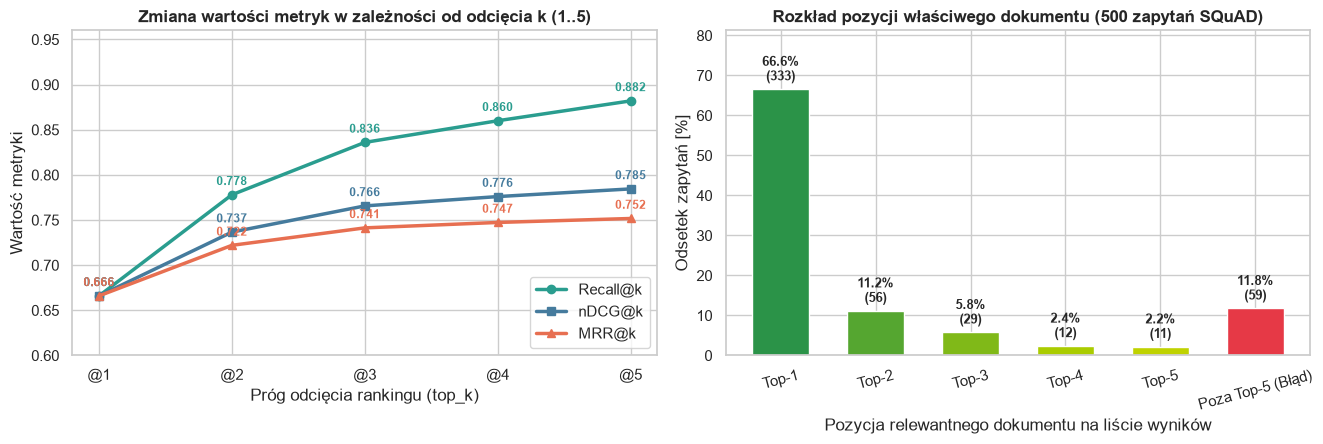

In [27]:
# 3.5 Pogłębiona analiza skuteczności Bi-Encodera: Krzywe @k oraz rozkład pozycji trafień
ks = [1, 2, 3, 4, 5]
curve_records = []
for k_val in ks:
    m_k = evaluate_rankings(rankings_faiss, qrels, k=k_val)
    curve_records.append(
        {
            "k": f"@{k_val}",
            "Recall@k": m_k[f"Recall@{k_val}"],
            "MRR@k": m_k[f"MRR@{k_val}"],
            "nDCG@k": m_k[f"nDCG@{k_val}"],
        }
    )
df_curves = pd.DataFrame(curve_records)

# Obliczenie na której pozycji (Top-1 .. Top-5 lub Brak) znalazł się właściwy dokument
rank_positions = []
for q_id, rel_docs in qrels.items():
    rel_set = set(rel_docs)
    retrieved = [doc_id for doc_id, _ in rankings_faiss.get(q_id, [])[:5]]
    found_rank = "Poza Top-5 (Błąd)"
    for r_idx, d_id in enumerate(retrieved, start=1):
        if d_id in rel_set:
            found_rank = f"Top-{r_idx}"
            break
    rank_positions.append(found_rank)

pos_order = ["Top-1", "Top-2", "Top-3", "Top-4", "Top-5", "Poza Top-5 (Błąd)"]
pos_counts = pd.Series(rank_positions).value_counts().reindex(pos_order, fill_value=0)
pos_perc = (pos_counts / len(qrels)) * 100

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))

# Panel 1: Krzywe Recall@k, nDCG@k, MRR@k dla k = 1..5
axes[0].plot(df_curves["k"], df_curves["Recall@k"], marker="o", linewidth=2.5, label="Recall@k", color="#2a9d8f")
axes[0].plot(df_curves["k"], df_curves["nDCG@k"], marker="s", linewidth=2.5, label="nDCG@k", color="#457b9d")
axes[0].plot(df_curves["k"], df_curves["MRR@k"], marker="^", linewidth=2.5, label="MRR@k", color="#e76f51")

for col, color in zip(["Recall@k", "nDCG@k", "MRR@k"], ["#2a9d8f", "#457b9d", "#e76f51"]):
    for idx, val in enumerate(df_curves[col]):
        axes[0].annotate(
            f"{val:.3f}",
            (df_curves["k"][idx], val),
            textcoords="offset points",
            xytext=(0, 7),
            ha="center",
            fontsize=8.5,
            color=color,
            fontweight="bold",
        )

axes[0].set_ylim(0.60, 0.96)
axes[0].set_title("Zmiana wartości metryk w zależności od odcięcia k (1..5)", fontweight="bold")
axes[0].set_xlabel("Próg odcięcia rankingu (top_k)")
axes[0].set_ylabel("Wartość metryki")
axes[0].legend(loc="lower right")

# Panel 2: Rozkład pozycji trafionego dokumentu (500 zapytań)
colors_pos = ["#2b9348", "#55a630", "#80b918", "#aacc00", "#bfd200", "#e63946"]
bars_pos = axes[1].bar(pos_order, pos_perc.values, color=colors_pos, edgecolor="white", width=0.6)
for bar, count in zip(bars_pos, pos_counts.values):
    h = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        h + 1.2,
        f"{h:.1f}%\n({count})",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

axes[1].set_ylim(0, max(pos_perc.values) * 1.22)
axes[1].set_title("Rozkład pozycji właściwego dokumentu (500 zapytań SQuAD)", fontweight="bold")
axes[1].set_xlabel("Pozycja relewantnego dokumentu na liście wyników")
axes[1].set_ylabel("Odsetek zapytań [%]")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### Wnioski z Punktu 3 (Porównanie bez indeksu vs FAISS)

1. **Zgodność wyników (Metryki jakości):**
   Zarówno wyszukiwanie bez indeksu (bezpośredni iloczyn skalarny macierzy osadzeń), jak i wyszukiwanie z użyciem indeksu `faiss.IndexFlatIP` uzyskują **identyczne wartości metryk** (`Recall@5`, `MRR@5`, `nDCG@5`). Wynika to z faktu, że `IndexFlatIP` przeprowadza dokładne przeszukiwanie (*exact search*) oparte na iloczynie skalarnym bez stratnej kwantyzacji wektorów.
2. **Wydajność i skalowalność:**
   Biblioteka FAISS (zoptymalizowana w C++ z wykorzystaniem instrukcji SIMD/BLAS oraz wielowątkowości OpenMP) pozwala na bardzo szybkie wyznaczenie $k$ najbliższych sąsiadów, a przy przejściu na miliony dokumentów umożliwia łatwą zamianę indeksu płaskiego na przybliżone indeksy grafowe lub oparte na odwróconych listach (`IndexIVFFlat`, `IndexHNSWFlat`), które redukują złożoność wyszukiwania kosztem minimalnego spadku pełności (Recall).
3. **Deduplikacja dokumentów:**
   Usunięcie duplikatów przed indeksowaniem jest kluczowe: w oryginalnym zbiorze SQuAD do jednego akapitu przypisanych jest średnio ~5 pytań. Bez deduplikacji wszystkie 5 miejsc na liście `top_k = 5` byłoby zajmowanych przez identyczne kopie tego samego akapitu, co sztucznie zaniżałoby `Recall@5` i uniemożliwiało rzetelną ewaluację.